# Birch affiniety propagation 



There is no single concept called "birch affinity" in machine learning; rather, the phrase usually combines two entirely distinct unsupervised clustering algorithms: BIRCH and Affinity Propagation

# for more information click the link below 

https://docs.google.com/document/d/1X3a0mUKqUo5PNbeNhaIyFtm11cW5Kz01lpqD2r-frAs/edit?usp=sharing

# Note and interview Q and A

https://docs.google.com/document/d/1napk5rhw0TTFbaC7l7KNhU-GjiE12hghIWez_0ybvEM/edit?usp=sharing

# Coding

`BIRCH = Balanced Iterative Reducing and Clustering using Hierarchies.`

`It is an unsupervised clustering algorithm designed especially for large datasets.`

# Dataset 

In [1]:
# NumPy → numerical calculations
import numpy as np

# Pandas → data manipulation
import pandas as pd

# Matplotlib → visualization
import matplotlib.pyplot as plt

# make_blobs → creates synthetic clustering data
from sklearn.datasets import make_blobs

# StandardScaler → standardizes features
from sklearn.preprocessing import StandardScaler

# Birch → BIRCH clustering algorithm
from sklearn.cluster import Birch

# Silhouette Score → evaluates clustering quality
from sklearn.metrics import silhouette_score

In [2]:
# Create the dataset 


X, y = make_blobs(
    n_samples=3000,                       # Generate 3000 observations
    centers=3,                            # Create 3 natural groups
    cluster_std=1.0,                      # Controls the spread of each group
    random_state=42                       # Makes the dataset reproducible
)

In [3]:
# Scale the data 

scaler = StandardScaler()                 # Creates the standardization object


X_scaled = scaler.fit_transform(
    X                                     # Standardizes the features
)

In [ ]:
# Create Brich 
# The main parameters we will care about are: 

# threshold
# ranching_factor
# n_clusters

birch = Birch(
    threshold=0.5,                         # Maximum radius allowed for a subcluster
    branching_factor=50,                   # Maximum number of CF entries in one tree node
    n_clusters=3                           # Number of final clusters
)

In [6]:
# Train BIRCH 

clusters = birch.fit_predict(
    X_scaled                              # Build the CF Tree and assign final clusters
)

In [7]:
# Evaluate BIRCH 

n_clusters = len(
    np.unique(clusters)                   # Count discovered clusters
)

print("Number of clusters:", n_clusters)


Number of clusters: 3


In [8]:
# then 

if n_clusters >= 2:                       # Silhouette requires at least two clusters

    score = silhouette_score(
        X_scaled,                         # Dataset
        clusters                          # Cluster assignments
    )

    print("Silhouette Score:", score)

else:

    print("Silhouette Score: N/A")

Silhouette Score: 0.8425061405248679


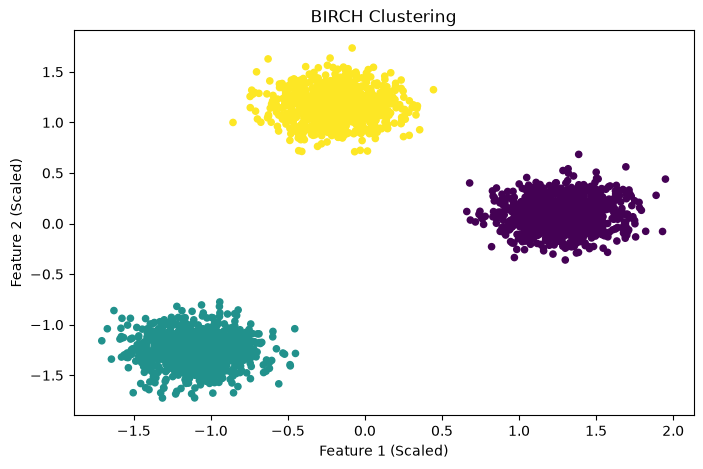

In [9]:
# Visualize BIRCH 


plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],                       # First feature
    X_scaled[:, 1],                       # Second feature
    c=clusters,                           # Color according to cluster
    s=20                                  # Point size
)

plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")
plt.title("BIRCH Clustering")

plt.show()


# BIRCH hyperparameter experiment 
`let's experiment with the most important parameter:`

`threshold`

In [ ]:
threshold_values = [
    0.2,
    0.3,
    0.5,
    0.7,
    1.0
]

for threshold in threshold_values:

    model = Birch(
        threshold=threshold,              # Test different subcluster radius limits
        branching_factor=50,              # Maximum CF entries per tree node
        n_clusters=3                       # Keep final cluster count fixed
    )

    labels = model.fit_predict(
        X_scaled                          # Build CF Tree and assign clusters
    )

    n_clusters = len(
        np.unique(labels)                 # Count final clusters
    )

    if n_clusters >= 2:

        score = silhouette_score(
            X_scaled,                     # Dataset
            labels                         # Cluster assignments
        )

        print(
            f"threshold={threshold} | "
            f"clusters={n_clusters} | "
            f"silhouette={score:.3f}"
        )

    else:

        print(
            f"threshold={threshold} | "
            f"clusters={n_clusters} | "
            f"silhouette=N/A"
        )


# BIRCH mental model 
#
#Large dataset
#      ↓
#Build CF Tree
#      ↓
#Compress nearby points
#      ↓
#Create subclusters
#      ↓
#Final clustering

# BIRCH is a scalable clustering algorithm that summarizes data using a hierarchical CF Tree before producing final clusters.

threshold=0.2 | clusters=3 | silhouette=0.843
threshold=0.3 | clusters=3 | silhouette=0.843
threshold=0.5 | clusters=3 | silhouette=0.843
threshold=0.7 | clusters=3 | silhouette=0.843
threshold=1.0 | clusters=3 | silhouette=0.843


# Affinity Propagation 

What is Affinity Propagation?

Affinity Propagation (AP) is an unsupervised clustering algorithm that identifies representative data points called exemplars.

Its main idea:

Instead of choosing cluster centers beforehand, data points communicate with each other and collectively determine which points should become representatives.

This is very different from K-Means.

In [ ]:
# What is an exemplar ?

# suppose  - ● ● ● ● ●

# One of those actual points may be selected as the representative:

# ● ● ★ ● ●
#      ↑
#   exemplar

# The other points are assigned according to their similarity to that exemplar.

 


# Dataset 

We'll again use a built-in scikit-learn dataset generator because Affinity Propagation works naturally with numerical similarity relationships.

In [11]:
# NumPy → numerical calculations
import numpy as np

# Pandas → data manipulation
import pandas as pd

# Matplotlib → visualization
import matplotlib.pyplot as plt

# make_blobs → creates synthetic clustering data
from sklearn.datasets import make_blobs

# StandardScaler → standardizes features
from sklearn.preprocessing import StandardScaler

# AffinityPropagation → Affinity Propagation clustering algorithm
from sklearn.cluster import AffinityPropagation

# Silhouette Score → evaluates clustering quality
from sklearn.metrics import silhouette_score

In [12]:
# Create the data:

X, y = make_blobs(
    n_samples=500,                        # Generate 500 observations
    centers=3,                            # Create 3 natural groups
    cluster_std=1.0,                      # Controls cluster spread
    random_state=42                       # Makes the dataset reproducible
)

In [15]:
# Scale 
scaler = StandardScaler()                 # Creates the standardization object

X_scaled = scaler.fit_transform(
    X                                     # Standardizes the features
)

In [ ]:
# Create affinity propagation 
# The most important parameter we will experiment with is: 
# Preference

affinity = AffinityPropagation(
    preference=None,                      # Controls how strongly points prefer becoming exemplars
    damping=0.7,                          # Controls message-update stability
    max_iter=500,                         # Maximum number of message-passing iterations
    convergence_iter=15,                  # Iterations used to determine convergence
    random_state=42                       # Makes the result reproducible
)

# What is preference ?
# This is the most important AP concept . 
# Every observation can potentially become as exemplar . 
# preference controls. 
# How much each point is preferred as a cluster representative ?


# Higher preference
#      ↓
#More points become exemplars
#       ↓
#More clusters

# Lower preference 
#ower preference
#       ↓
#Fewer exemplars
#       ↓
#Fewer clusters

In [ ]:
# What is damping ? 
# affinity propagation exchanges messages between observations . 


In [17]:
# train affinity propagation 

clusters = affinity.fit_predict(
    X_scaled                              # Exchange messages and determine exemplars/clusters
)

In [18]:
# number of cluster 
n_clusters = len(
    np.unique(clusters)                   # Count the discovered clusters
)

print("Number of clusters:", n_clusters)

Number of clusters: 4


In [19]:
# Evaluate 

if n_clusters >= 2:

    score = silhouette_score(
        X_scaled,                         # Dataset
        clusters                          # Cluster assignments
    )

    print("Silhouette Score:", score)

else:

    print("Silhouette Score: N/A")

Silhouette Score: 0.6807043932260801


In [21]:
# Find the exemplars 
# this is one of the coolest parts of affinity propagation 

exemplar_indices = affinity.cluster_centers_indices_

# THese are the indices of the actual obesrvation selected as exemplars . 

print("Exemplar indices:")
print(exemplar_indices)

Exemplar indices:
[229 405 449 462]


In [22]:
exemplars = X_scaled[
    exemplar_indices                     # Extract the actual representative observations
]

print("Exemplars:")
print(exemplars)

Exemplars:
[[ 1.13941929  0.05207654]
 [ 1.46971045  0.11285043]
 [-0.20011536  1.18118623]
 [-1.07949253 -1.24821549]]


# Visualize affinity propagation 

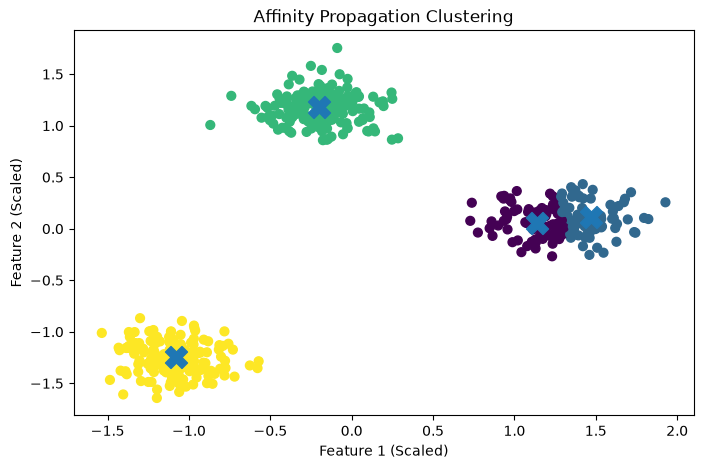

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],                       # First feature
    X_scaled[:, 1],                       # Second feature
    c=clusters,                           # Color according to cluster
    s=40                                  # Point size
)

plt.scatter(
    exemplars[:, 0],                      # Exemplar X-coordinates
    exemplars[:, 1],                      # Exemplar Y-coordinates
    marker="X",                           # Display exemplars as X
    s=250                                 # Make exemplars larger
)

plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")
plt.title("Affinity Propagation Clustering")

plt.show()

# Hyperparameter experiment - preference 

In [29]:
preference_values = [
    -10,
    -5,
    -3,
    -2,
    -1
]

for preference in preference_values:

    model = AffinityPropagation(
        preference=preference,             # Controls how strongly points become exemplars
        damping=0.7,                       # Stabilizes message updates
        max_iter=500,                      # Maximum number of iterations
        convergence_iter=15,               # Checks whether the algorithm has converged
        random_state=42                    # Makes the result reproducible
    )

    labels = model.fit_predict(
        X_scaled                          # Perform Affinity Propagation
    )

    n_clusters = len(
        np.unique(labels)                 # Count the discovered clusters
    )

    if 2 <= n_clusters < len(X_scaled):   # Silhouette requires 2 to n_samples-1 clusters

        score = silhouette_score(
            X_scaled,                     # Dataset
            labels                        # Cluster assignments
        )

        print(
            f"preference={preference} | "
            f"clusters={n_clusters} | "
            f"silhouette={score:.3f}"
        )

    else:

        print(
            f"preference={preference} | "
            f"clusters={n_clusters} | "
            f"silhouette=N/A"
        )

preference=-10 | clusters=3 | silhouette=0.844
preference=-5 | clusters=4 | silhouette=0.681
preference=-3 | clusters=6 | silhouette=0.338
preference=-2 | clusters=7 | silhouette=0.331
preference=-1 | clusters=13 | silhouette=0.342
